# 2. Polarization (DFU)

DFU is 0 for a unimodal histogram of ratings and grows as the ratings split into two camps.

In [1]:
from perspective_audit import Unimodality

tool = Unimodality()                                     # ratings 1-5, tolerance 0
examples = {"all civil": [1, 1, 2, 1, 2, 1], "mild": [1, 2, 2, 3, 3, 2], "split 1 vs 5": [1, 1, 1, 5, 5, 5], "split 2 vs 4": [2, 2, 2, 4, 4, 4]}
{name: round(tool.dfu(r), 3) for name, r in examples.items()}

{'all civil': 0.0, 'mild': 0.0, 'split 1 vs 5': 1.0, 'split 2 vs 4': 1.0}

## The histograms

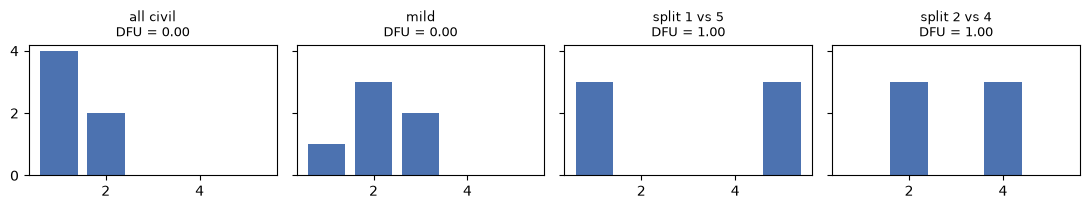

In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(examples), figsize=(11, 2.2), sharey=True)
for ax, (name, ratings) in zip(axes, examples.items()):
    ax.bar(range(1, 6), [ratings.count(k) for k in range(1, 6)], color="#4C72B0")
    ax.set_title(f"{name}\nDFU = {tool.dfu(ratings):.2f}", fontsize=9)
plt.tight_layout()

## On a dataset

The DFU of every text of the toy dataset. Consensus texts are 0, the polarized ones are above 0.

In [3]:
from perspective_audit import run_dataset
from perspective_audit.toy import toy_ratings, toy_spec

result = run_dataset(toy_spec(), raw=toy_ratings())
texts = result.tool.analyse(result.clean, "item_id", "rating", "politics")
texts[["item_id", "dfu", "polarised"]].head(9)

,item_id,dfu,polarised
0,t0,0.000000,False
1,t1,0.750000,True
2,t2,0.500000,True
3,t3,0.000000,False
4,t4,0.857143,True
5,t5,0.500000,True
6,t6,0.000000,False
7,t7,0.875000,True
8,t8,0.875000,True
